# Exploração da sazonalidade de lançamentos

**Pergunta de pesquisa:** Existe sazonalidade no lançamento de jogos? Jogos lançados em determinados meses/trimestres tendem a ter mais proprietários estimados ou maior tempo médio de jogo?

**Responsável:** Eloy Ribeiro Pereira Maciel

## Configuração

Funciona localmente e no Google Colab.

In [92]:
import os, sys
from pathlib import Path

if "google.colab" in sys.modules:
    REPO = "/content/tp_ciencia_de_dados"
    if not os.path.exists(REPO):
        !git clone -q https://github.com/pbarruetavena/tp_ciencia_de_dados.git {REPO}
    else:
        !git -C {REPO} pull -q --ff-only
    %cd {REPO}
    !pip install -q kagglehub
    !python -m src.download_data
    sys.path.insert(0, os.getcwd())
else:
    # Permite importar src/ a partir de notebooks/<pasta>/
    sys.path.insert(0, str(Path.cwd().parents[1]))

/content/tp_ciencia_de_dados
Versão 83 disponível em: /content/tp_ciencia_de_dados/data/raw


In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np


from src.config import FIGURAS
from src.dados import carregar_jogos
from src.limpeza import com_reviews_minimas, filtrar_iqr, limpar

jogos = limpar(carregar_jogos())
jogos.shape

(144240, 67)

## Análise exploratória

A pergunta que temos interesse em responder pode ser dividida em duas partes:

a. Sazonalidade de lançamentos: existe um padrão na contagem de jogos lançados por mês/trimestre?

b. Desempenho por período: jogos lançados em certos meses/trimestres têm mais `owners_mid` ou maior `average_playtime_forever`?

In [3]:
jogos.head()

,app_id,name,release_date,price,price_status,estimated_owners,developers,publishers,genres,categories,...,genero_simulation,genero_strategy,genero_rpg,genero_free_to_play,genero_early_access,genero_sports,log_price,log_reviews,log_playtime,log_owners
0,2733000,Club Chairman,2026-08-14,2.99,paid,"0 .. 20,000",[Ashina Games],[Ashina Games],"[Casual, Indie, Simulation, Sports, Strategy]","[Single-player, Custom Volume Controls, #categ...",...,True,True,False,False,False,True,1.383791,0.0,NaN,9.21044
1,3130050,Stellar Odyssey,2026-08-14,14.99,paid,"0 .. 20,000",[Warp Studios Pty Ltd],[Warp Studios Pty Ltd],"[Action, Adventure, Indie, Massively Multiplay...","[Single-player, Multi-player, MMO, PvP, Online...",...,False,True,True,False,True,False,2.771964,0.0,NaN,9.21044
2,2566840,Sands of Skullcreek,2026-08-14,0.00,free,"0 .. 20,000",[Fallen Sun Arcade],[Fallen Sun Arcade],"[Action, Casual, Indie, Free To Play]","[Single-player, Partial Controller Support, Fa...",...,False,False,False,True,False,False,0.000000,0.0,NaN,9.21044
3,2507500,Bounty Hunters,2026-08-15,5.00,paid,"0 .. 20,000",[AntiCodec],[AntiCodec],"[Action, Adventure, Indie, Early Access]","[Single-player, Steam Achievements, Family Sha...",...,False,False,False,False,True,False,1.791759,0.0,NaN,9.21044
4,2825810,PhotoGuessr,2026-08-15,3.99,paid,"0 .. 20,000",[Studio Pakira],[Studio Pakira],[Casual],"[Single-player, Steam Achievements, Steam Lead...",...,False,False,False,False,False,False,1.607436,0.0,NaN,9.21044


### Busca por sazonalidade

Começamos tentando enteder o lançamento de jogos por ano.

In [20]:
print(f"NaT em release_date: {jogos["release_date"].isna().sum()}, {(jogos["release_date"].isna().sum()/jogos["release_date"].size)*100:.3f}%")
print("min/max:", jogos["release_date"].min(), jogos["release_date"].max())

contagem_ano = jogos["ano"].value_counts().sort_index()
print(contagem_ano.tail(20))

NaT em release_date: 82, 0.057%
min/max: 1997-06-30 00:00:00 2026-10-20 00:00:00
ano
2007       90
2008      158
2009      321
2010      255
2011      258
2012      322
2013      467
2014     1521
2015     2513
2016     4137
2017     5918
2018     7449
2019     7236
2020     8793
2021    11044
2022    12255
2023    14539
2024    19899
2025    24688
2026    22198
Name: count, dtype: Int64


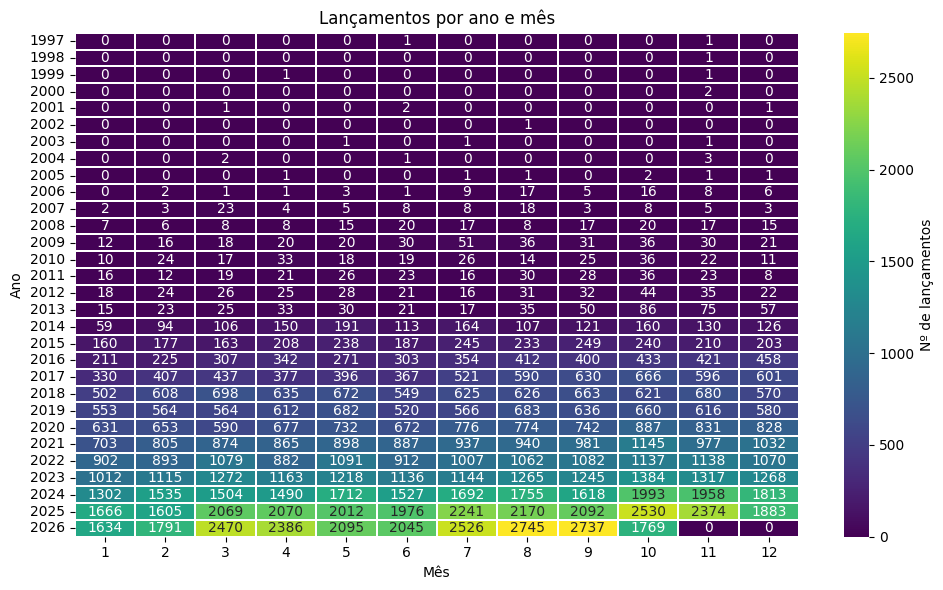

In [93]:
tabela = pd.crosstab(jogos["ano"], jogos["mes"])

fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(
    tabela.drop(index="Total", columns="Total", errors="ignore"),
    cmap="viridis",
    annot=True,
    fmt="d",
    linewidths=0.3,
    cbar_kws={"label": "Nº de lançamentos"},
    ax=ax,
)
ax.set(title=f"Lançamentos por ano e mês",
       xlabel="Mês", ylabel="Ano")
plt.tight_layout()
fig.savefig(FIGURAS / "heatmap_ano_mes.png", dpi=150, bbox_inches="tight")

Antes de 2014, a base tem menos de 500 lançamentos por ano, isso torna a série mensal ruidosa e sensível a poucos jogos. Por isso, restringimos a análise a 2014–2025. O ano de 2026 foi excluído por estar incompleto (o snapshot é de outubro/2026), o que geraria meses com contagem artificialmente baixa

In [44]:
JANELA_INICIO = 2014
JANELA_FIM = 2025
jogos_janela = jogos[(jogos["ano"] >= JANELA_INICIO) & (jogos["ano"] <= JANELA_FIM)].copy()

In [59]:
tabela = pd.crosstab(jogos_janela["ano"], jogos_janela["mes"])

mes,1,2,3,4,5,6,7,8,9,10,11,12,Total
ano,,,,,,,,,,,,,
2014,59,94,106,150,191,113,164,107,121,160,130,126,1521
2015,160,177,163,208,238,187,245,233,249,240,210,203,2513
2016,211,225,307,342,271,303,354,412,400,433,421,458,4137
2017,330,407,437,377,396,367,521,590,630,666,596,601,5918
2018,502,608,698,635,672,549,625,626,663,621,680,570,7449
2019,553,564,564,612,682,520,566,683,636,660,616,580,7236
2020,631,653,590,677,732,672,776,774,742,887,831,828,8793
2021,703,805,874,865,898,887,937,940,981,1145,977,1032,11044
2022,902,893,1079,882,1091,912,1007,1062,1082,1137,1138,1070,12255


In [60]:
contagem_ano = jogos["ano"].value_counts().sort_index()
print(contagem_ano.tail(15))

ano
2012      322
2013      467
2014     1521
2015     2513
2016     4137
2017     5918
2018     7449
2019     7236
2020     8793
2021    11044
2022    12255
2023    14539
2024    19899
2025    24688
2026    22198
Name: count, dtype: Int64


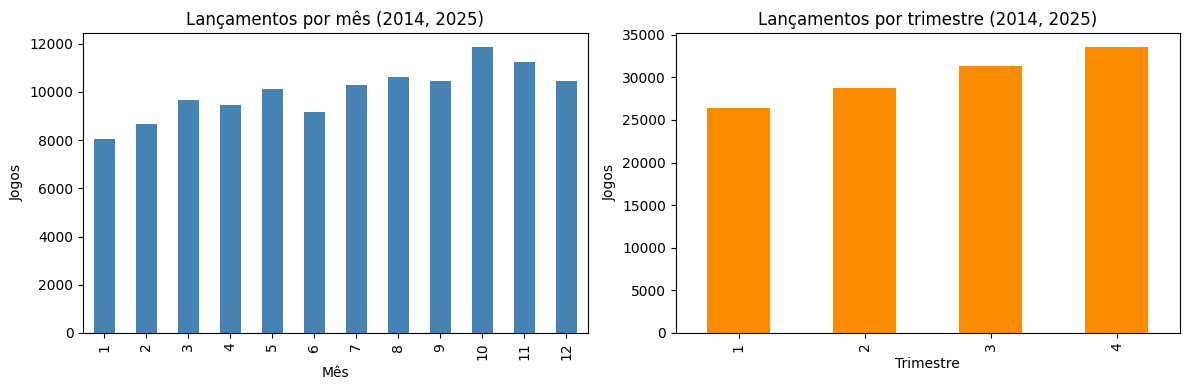

In [94]:
por_mes = jogos_janela["mes"].value_counts().sort_index()
por_trim = jogos_janela["trimestre"].value_counts().sort_index()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
por_mes.plot(kind="bar", ax=axes[0], color="steelblue")
axes[0].set(title=f"Lançamentos por mês ({JANELA_INICIO}, {JANELA_FIM})", xlabel="Mês", ylabel="Jogos")

por_trim.plot(kind="bar", ax=axes[1], color="darkorange")
axes[1].set(title=f"Lançamentos por trimestre ({JANELA_INICIO}, {JANELA_FIM})", xlabel="Trimestre", ylabel="Jogos")
fig.savefig(FIGURAS / "lancamentos_ano_mes.png", dpi=150, bbox_inches="tight")
plt.tight_layout()


O gráfico mostra concentração de lançamentos entre agosto e dezembro, com vale em janeiro. A seguir, verificamos o quanto esse padrão é estável entre os anos, para separar sazonalidade estrutural de ruído de um ano específico.

In [63]:
prop_por_ano = (
    pd.crosstab(jogos_janela["ano"], jogos_janela["mes"], normalize="index")
)
media_prop = prop_por_ano.mean()  # cada ano pesa igual
print(media_prop.round(3))
print(f"razão max/min: {media_prop.max() / media_prop.min():.2f}")

mes
1     0.064
2     0.071
3     0.078
4     0.080
5     0.087
6     0.075
7     0.088
8     0.089
9     0.089
10    0.099
11    0.092
12    0.089
dtype: float64
razão max/min: 1.55


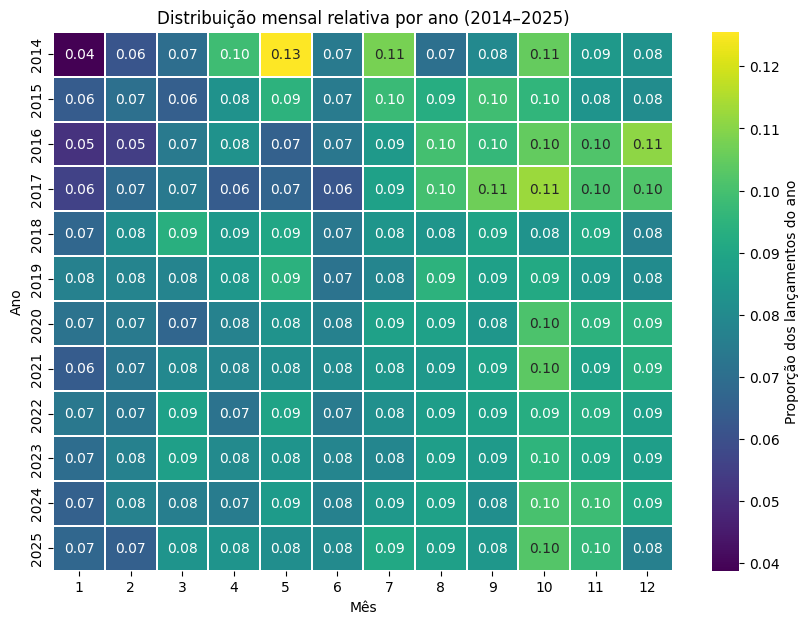

In [96]:
fig, ax = plt.subplots(figsize=(10, 7))
sns.heatmap(prop_por_ano, cmap="viridis", annot=True, fmt=".2f",
            linewidths=0.3, cbar_kws={"label": "Proporção dos lançamentos do ano"}, ax=ax)
ax.set(title="Distribuição mensal relativa por ano (2014–2025)",
       xlabel="Mês", ylabel="Ano")
fig.savefig(FIGURAS / "distribuicao_mes_ano.png", dpi=150, bbox_inches="tight")

In [67]:
cv_por_mes = prop_por_ano.std() / prop_por_ano.mean()
print(cv_por_mes.round(3).sort_values(ascending=False))

mes
5     0.176
1     0.166
12    0.117
3     0.114
2     0.108
4     0.106
7     0.094
8     0.088
9     0.087
10    0.078
11    0.066
6     0.064
dtype: float64


In [66]:
std_abs = prop_por_ano.std()
print(std_abs.round(4).sort_values(ascending=False))

mes
5     0.0153
1     0.0106
12    0.0104
3     0.0089
4     0.0085
7     0.0082
10    0.0078
8     0.0078
9     0.0078
2     0.0077
11    0.0061
6     0.0048
dtype: float64


O coeficiente de variação (CV) e o desvio-padrão absoluto mostram que maio é o mês mais instável (CV 0,176; DP 0,015) e junho o mais estável (CV 0,064; DP 0,005), seguido de novembro (CV 0,066). Janeiro, o vale em média, também varia bastante (CV 0,166) — ser o menor em média não significa ser o menor em todos os anos. Outubro, o pico, tem CV baixo (0,078), então o padrão de pico é mais consistente que o de vale.

Há um pico em outubro (que permanece alto em novembro), recuo em dezembro e mínimo em janeiro. Uma hipótese é que publishers evitem a temporada de festas por causa da concorrência com AAA, mas que os dados deste trabalho não permitem confirmar. A magnitude é moderada: outubro recebe cerca de 55% mais lançamentos que janeiro

In [74]:
dias = pd.Series({1:31, 2:28.25, 3:31, 4:30, 5:31, 6:30,
                  7:31, 8:31, 9:30, 10:31, 11:30, 12:31})
taxa_dia = media_prop / dias
taxa_dia = taxa_dia / taxa_dia.sum()

indice = taxa_dia * 12
print(indice.round(4).sort_values(ascending=False))
print(f"razão max/min: {indice.max() / indice.min():.2f}")

mes
10    1.1665
11    1.1254
9     1.0878
8     1.0447
12    1.0431
7     1.0321
5     1.0235
4     0.9780
2     0.9202
3     0.9187
6     0.9090
1     0.7509
dtype: float64
razão max/min: 1.55


In [76]:
comparacao = pd.DataFrame({
    "media_prop_x12": (media_prop * 12).round(3),
    "indice_dia":     indice.round(3),
})
comparacao["dif_%"] = ((comparacao["indice_dia"] / comparacao["media_prop_x12"] - 1) * 100).round(1)
print(comparacao.sort_values("indice_dia", ascending=False))

     media_prop_x12  indice_dia  dif_%
mes                                   
10            1.188       1.166   -1.9
11            1.109       1.125    1.4
9             1.072       1.088    1.5
8             1.064       1.045   -1.8
12            1.062       1.043   -1.8
7             1.051       1.032   -1.8
5             1.042       1.023   -1.8
4             0.964       0.978    1.5
2             0.854       0.920    7.7
3             0.935       0.919   -1.7
6             0.896       0.909    1.5
1             0.765       0.751   -1.8


O índice ajustado por dias confirma a leitura: outubro concentra 17% mais lançamentos que a média (índice 1,17) e janeiro 25% menos (índice 0,75), com razão pico/vale de 1,55. Como outubro e janeiro têm ambos 31 dias, a razão é a mesma antes e depois do ajuste; a única mudança relevante é fevereiro (+8%, por ter 28,25 dias).

A regressão linear da fatia de cada mês ao longo de 2014–2025, apresentada abaixo, não revela tendência sistemática: nenhum mês apresenta slope significativo após correção para múltiplos testes (Holm). A maior alteração (medida pelo slope) é janeiro (+0,0019/ano), mas não sobrevive à correção. Isso confirma que o padrão sazonal é estável no período, sem deriva

In [77]:
from scipy.stats import linregress

for m in range(1, 13):
    slope, _, r, p, _ = linregress(prop_por_ano.index, prop_por_ano[m])
    print(f"mês {m:2d}: slope={slope:+.4f}/ano, p={p:.3f}")

mês  1: slope=+0.0019/ano, p=0.026
mês  2: slope=+0.0008/ano, p=0.201
mês  3: slope=+0.0013/ano, p=0.089
mês  4: slope=-0.0008/ano, p=0.257
mês  5: slope=-0.0013/ano, p=0.345
mês  6: slope=+0.0007/ano, p=0.070
mês  7: slope=-0.0013/ano, p=0.060
mês  8: slope=-0.0000/ano, p=0.984
mês  9: slope=-0.0010/ano, p=0.146
mês 10: slope=-0.0003/ano, p=0.678
mês 11: slope=+0.0005/ano, p=0.382
mês 12: slope=-0.0005/ano, p=0.570


Força da sazonalidade: 0.530


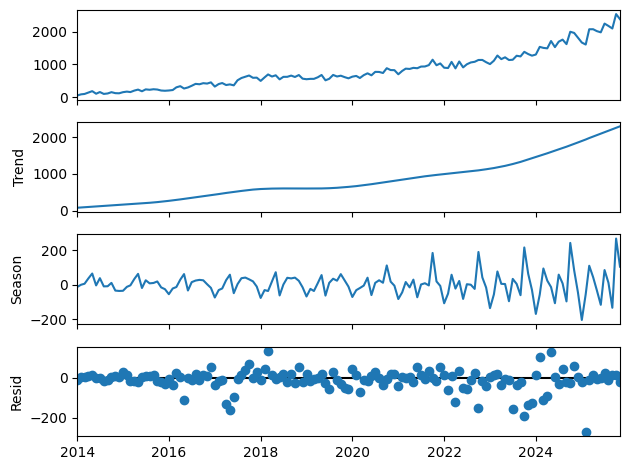

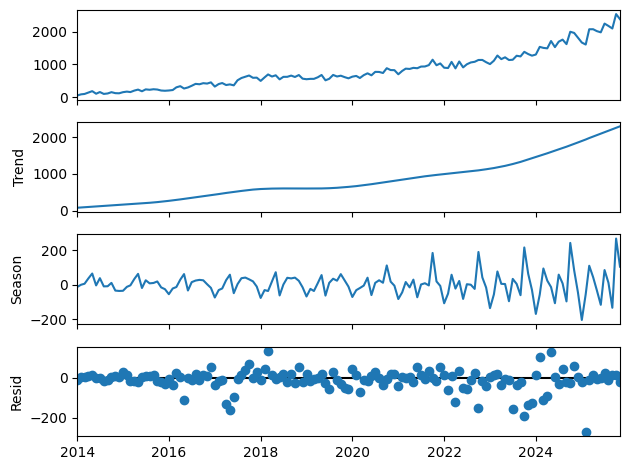

In [99]:
from statsmodels.tsa.seasonal import STL

serie = (jogos_janela.dropna(subset=["release_date"])
         .set_index("release_date").resample("MS").size())
serie = serie.iloc[:-1]

stl = STL(serie, period=12, robust=True).fit()
stl.plot()
fig = stl.plot()
fig.savefig(FIGURAS / "decomposicao_stl_lancamentos.png", dpi=150, bbox_inches="tight")

var_r = np.var(stl.resid, ddof=1)
var_rs = np.var(stl.seasonal + stl.resid, ddof=1)
print(f"Força da sazonalidade: {max(0, 1 - var_r/var_rs):.3f}")

Existe sazonalidade nos lançamentos da Steam, moderada e estável. Outubro concentra 17% mais lançamentos que a média e janeiro 25% menos (razão 1,55), já descontando a duração dos meses. O heatmap mostra perfil semelhante em todos os anos, e o CV por mês fica abaixo de 0,18, indicando padrão estrutural. A série temporal confirma força de sazonalidade de 0,53. Esses resultados descrevem quando os jogos são lançados.

### Desempenho por período

Temos duas escolhas de desenho, antes dos números:

**Trimestre em vez de mês.** Agrupar por trimestre aumenta o N por célula
(4 grupos em vez de 12, \~3× mais jogos por grupo) e reduz ruído de composição
mensal. O padrão da primeira pergunta já está capturado em 4 trimestres (Q4 = out–nov–dez é o pico; Q1 = jan–mar é o vale), então não se perde a informação relevante.

**`average_playtime_forever` é análise secundária por construção.** Após a limpeza, \~93% dos jogos têm esse campo como `NaN` (zero = sem dado de jogadores, não ausência de jogadores). O tamanho N da amostra por trimestre vai despencar e ficar enviesado para jogos com jogadores reais, provavelmente indies grandes e AAAs, que não são representativos dos lançamentos da base. Por isso, o resultado de playtime **não será tratado como achado principal**: é um sinal complementar, com N por grupo reportado e ressalva explícita se o N por trimestre ficar abaixo de um piso (\~5.000).

**Hipóteses para `log_owners`:**
- **H₀:** a distribuição de `log_owners` é igual nos quatro trimestres.
- **H₁:** ao menos um trimestre tem distribuição diferente.
- **Teste:** Kruskal-Wallis (cauda longa, outliers tipo CS:GO/Dota) + OLS com dummies de trimestre e controle por ano, para separar "efeito de trimestre" de "efeito de época"
(Steam cresce muito entre 2014 e 2025, e Q4 concentra lançamentos recentes — sem `C(ano)`, trimestre captura época).
- **α = 0,05.**

In [79]:
amostra = jogos_janela.dropna(subset=["log_owners", "ano"]).copy()
amostra["trimestre"] = amostra["trimestre"].astype(int)
amostra["ano"] = amostra["ano"].astype(int)

print(f"N janela 2014–2025: {len(jogos_janela):,}")
print(f"N amostra (log_owners + ano): {len(amostra):,} "
      f"({len(amostra)/len(jogos_janela)*100:.1f}%)")
print("\nN por trimestre (owners):")
print(amostra.groupby("trimestre").size().rename("n"))

print("\n--- Checagem de playtime (análise secundária) ---")
amostra_playtime = jogos_janela.dropna(subset=["log_playtime", "ano"]).copy()
print(f"N com log_playtime + ano: {len(amostra_playtime):,} "
      f"({len(amostra_playtime)/len(jogos_janela)*100:.1f}%)")
print("\nN por trimestre (playtime):")
print(amostra_playtime.groupby("trimestre").size().rename("n"))

N janela 2014–2025: 119,992
N amostra (log_owners + ano): 98,862 (82.4%)

N por trimestre (owners):
trimestre
1    22873
2    23983
3    25142
4    26864
Name: n, dtype: int64

--- Checagem de playtime (análise secundária) ---
N com log_playtime + ano: 10,258 (8.5%)

N por trimestre (playtime):
trimestre
1    2190
2    2508
3    2746
4    2814
Name: n, dtype: int64


A amostra de `log_owners` mantém **82,4%** dos lançamentos da janela
(98.862 de 119.992), com N equilibrado entre trimestres (22.873–26.864).
A perda está espalhada entre os trimestres, então a amostra é
representativa dos lançamentos da base.

A amostra de `log_playtime` cai para **8,5%** (10.258 jogos), como previsto
pela limpeza. O N por trimestre (2.190–2.814) é suficiente para
Kruskal-Wallis, mas não para OLS com controle por ano, e a amostra é
enviesada para jogos com jogadores reais. Por isso, playtime entra como análise exploratória (KW + boxplot), com ressalva explícita no fechamento. A análise principal é sobre `log_owners`.

Também tentamos descrever a amostra através de gráficos e tabelas:

In [80]:
desc = (amostra
        .groupby("trimestre")["log_owners"]
        .agg(n="size", mediana="median", media="mean",
             q25=lambda s: s.quantile(.25),
             q75=lambda s: s.quantile(.75)))
desc["iqr"] = desc["q75"] - desc["q25"]
print(desc.round(3))

               n  mediana  media   q25   q75  iqr
trimestre                                        
1          22873     9.21  9.743  9.21  9.21  0.0
2          23983     9.21  9.750  9.21  9.21  0.0
3          25142     9.21  9.735  9.21  9.21  0.0
4          26864     9.21  9.696  9.21  9.21  0.0


trimestre
1    24.83
2    24.78
3    24.35
4    22.48
Name: % acima de 20k donos, dtype: float64


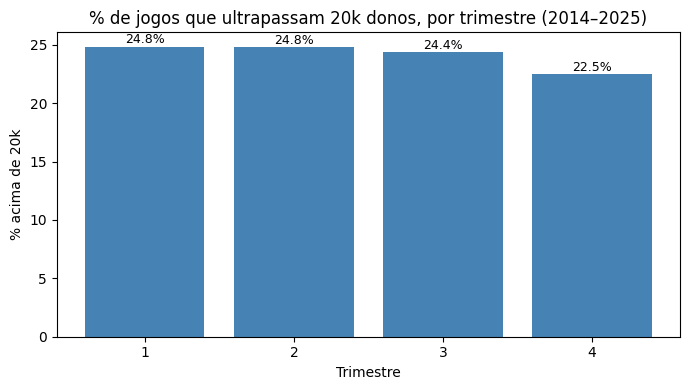

In [97]:
escape = (
    amostra.assign(acima_20k=amostra["owners_mid"] > 20_000)
    .groupby("trimestre")["acima_20k"]
    .mean()
    .mul(100)
    .round(2)
)

print(escape.rename("% acima de 20k donos"))

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(escape.index, escape.values, color="steelblue")
ax.set_xticks([1, 2, 3, 4])
ax.set(title="% de jogos que ultrapassam 20k donos, por trimestre (2014–2025)",
       xlabel="Trimestre", ylabel="% acima de 20k")
for b, v in zip(bars, escape.values):
    ax.text(b.get_x() + b.get_width()/2, v + 0.3, f"{v:.1f}%",
            ha="center", fontsize=9)
plt.tight_layout()
fig.savefig(FIGURAS / "grafico_escape.png", dpi=150, bbox_inches="tight")

A tabela descritiva apresentada revela que mediana, Q25 e Q75 são idênticos em todos os trimestres (9,21), com IQR = 0. Isso ocorre porque mais de 75% dos jogos estão no piso da base (0–20k donos). Como as métricas de tendência central não diferenciam os trimestres, resumimos a comparação na taxa de escape, isso é, a proporção de jogos que ultrapassam 20k donos.

O gráfico mostra Q1 = 24,8%, Q2 = 24,8%, Q3 = 24,3% e Q4 = 22,5%. A diferença é modesta (2,3 p.p. entre Q1 e Q4), mas já indica o sentido oposto ao intuitivo.

In [82]:
from scipy.stats import kruskal

grupos = [g["log_owners"].values for _, g in amostra.groupby("trimestre")]
H, p = kruskal(*grupos)
k = len(grupos)
n = len(amostra)
eps2 = (H - k + 1) / (n - k)  # tamanho de efeito para Kruskal-Wallis

print(f"Kruskal-Wallis: H = {H:.2f}, gl = {k-1}, p = {p:.4g}")
print(f"ε² = {eps2:.4f}  (~variância explicada pelo trimestre)")

Kruskal-Wallis: H = 52.90, gl = 3, p = 1.926e-11
ε² = 0.0005  (~variância explicada pelo trimestre)


In [83]:
import statsmodels.formula.api as smf

# Modelo 1: ingênuo — confunde trimestre com época
m1 = smf.ols("log_owners ~ C(trimestre)", data=amostra).fit()

# Modelo 2: trimestre + controle por ano — resposta real
m2 = smf.ols("log_owners ~ C(trimestre) + C(ano)", data=amostra).fit()

comp = pd.DataFrame({
    "ingenuo":      m1.params.filter(like="trimestre"),
    "p_ingenuo":    m1.pvalues.filter(like="trimestre"),
    "controlado":   m2.params.filter(like="trimestre"),
    "p_controlado": m2.pvalues.filter(like="trimestre"),
})
print(comp.round(4))
print(f"\nR² m1 = {m1.rsquared:.4f}  |  R² m2 = {m2.rsquared:.4f}")
print(f"ΔR² ao adicionar ano = {m2.rsquared - m1.rsquared:.4f}")

                   ingenuo  p_ingenuo  controlado  p_controlado
C(trimestre)[T.2]   0.0062     0.5371     -0.0150         0.115
C(trimestre)[T.3]  -0.0080     0.4187     -0.0541         0.000
C(trimestre)[T.4]  -0.0479     0.0000     -0.0905         0.000

R² m1 = 0.0004  |  R² m2 = 0.1028
ΔR² ao adicionar ano = 0.1024


Ao ler o resultado do OLS no modelo ingênuo (só trimestre), o efeito é fraco ($R² = 0,0004$): Q2 ($+0,006$) e Q3 ($-0,008$) não diferem de Q1; apenas Q4
é significativo ($-0,048$). Ao adicionar `C(ano)`, os coeficientes
amplificam em vez de cair: Q3 passa a $-0,054$ (agora significativo)
e Q4 a $-0,091$ (segue significativo). O modelo ingênuo estava, portanto,
mascarando o efeito de trimestre.

O $ΔR²$ de $0,1024$ mostra que é o ano que explica ~10% da variância;
trimestre sozinho explica $0,04\%$. A leitura correta: no mesmo ano, jogos
lançados em Q3/Q4 têm $~5–9\%$ menos donos que jogos de Q1 (coeficientes
$-0,054$ e $-0,091$ em log).

O trimestre tem efeito estatisticamente significativo sobre owners_mid após controlar por ano, mas de magnitude modesta (5–9% no mesmo ano) e contribuição pequena em variância explicada. O sentido
é **oposto ao intuitivo**: Q3/Q4 têm menos donos que Q1. Porém os dois padrões
se encaixam: Q4 concentra mais lançamentos (razão pico/vale 1,55),
mas cada jogo de Q4 tem menos donos em média. Consistente com
competição: mais jogos disputando a mesma atenção → menos donos
por jogo. A sazonalidade de publicação se traduz em diferença de
desempenho negativamente.

O OLS controla o ano, mas não o tempo de
mercado dentro do ano. Q4/2025 teve ~10 meses menos de exposição que
Q1/2025, e `owners_mid` satura no piso (0–20k). Parte do coeficiente
negativo de Q4 pode ser maturação, não sazonalidade.

Kruskal-Wallis (playtime): H = 8.44, p = 0.03777
ε² = 0.0005

N por trimestre (playtime):
trimestre
1    2190
2    2508
3    2746
4    2814
Name: n, dtype: int64


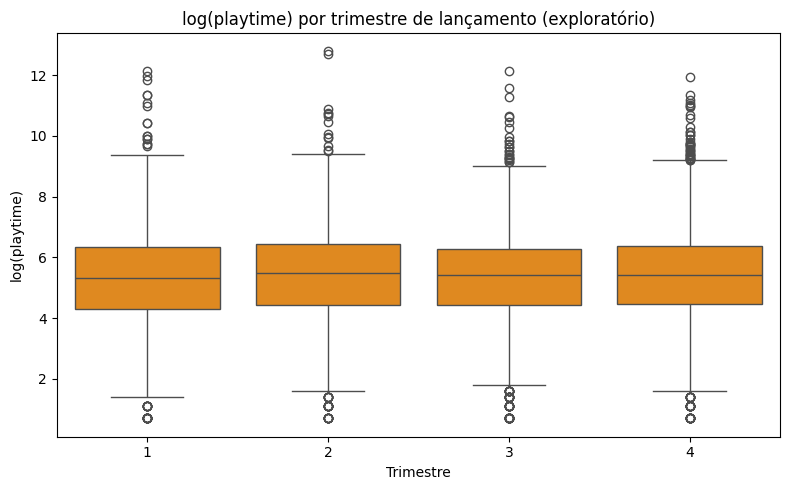

In [98]:
grupos_pt = [g["log_playtime"].values
             for _, g in amostra_playtime.groupby("trimestre")]
H_pt, p_pt = kruskal(*grupos_pt)
k_pt = len(grupos_pt)
n_pt = len(amostra_playtime)
eps2_pt = (H_pt - k_pt + 1) / (n_pt - k_pt)

print(f"Kruskal-Wallis (playtime): H = {H_pt:.2f}, p = {p_pt:.4g}")
print(f"ε² = {eps2_pt:.4f}")
print("\nN por trimestre (playtime):")
print(amostra_playtime.groupby("trimestre").size().rename("n"))

fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=amostra_playtime, x="trimestre", y="log_playtime",
            color="darkorange", ax=ax)
ax.set(title="log(playtime) por trimestre de lançamento (exploratório)",
       xlabel="Trimestre", ylabel="log(playtime)")
fig.savefig(FIGURAS / "boxplot_log_playtime_trimestre.png", dpi=150, bbox_inches="tight")
plt.tight_layout()

`average_playtime_forever` entrou como **análise secundária**, não como
achado principal, ele serve como sinal complementar, com ressalva explícita.

**Resultado.** Kruskal-Wallis em `log_playtime` rejeita H₀
(H = 8,44, gl = 3, p = 0,038 < 0,05), mas o ε² de 0,0005 indica
**efeito desprezível** — trimestre explica ~0,05% da variância dos
ranks. Com N = 10.258, o p-valor é sensível a diferenças minúsculas:
significância estatística não é relevância prática.

**N por trimestre:** 2.190 (Q1), 2.508 (Q2), 2.746 (Q3), 2.814 (Q4) —
suficiente para o teste, mas a amostra é **enviesada por construção**
(93% dos jogos foram removidos por NaN em playtime; os que sobraram são
sistematicamente jogos com jogadores reais).

**Conclusão.** Não há sinal interpretável de sazonalidade em
`average_playtime_forever`: o teste é estatisticamente significativo
mas o efeito é desprezível, e a amostra não é representativa do
universo de lançamentos. Este resultado **não entra na conclusão
principal da 3.2** — é sinal exploratório, não achado. A análise
principal é sobre `log_owners`.